In [4]:
import micropip
await micropip.install('PyWavelets')
print(" PyWavelets установлен")

 PyWavelets установлен


In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print(" Импорты выполнены (без pywt — ручная реализация)")

 Импорты выполнены (без pywt — ручная реализация)


Изображение загружено: (512, 512)
   min=5, max=255, mean=134.59


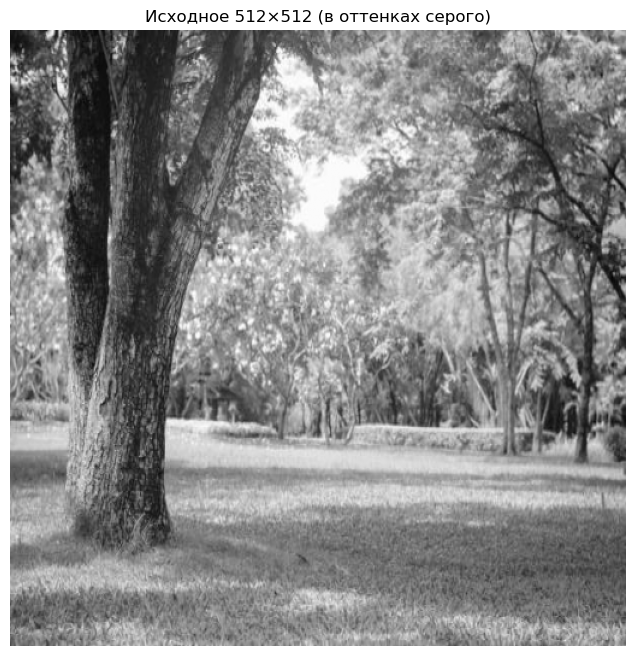

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

#ТОЧНОЕ имя файла (с пробелом и скобками)
img = cv2.imread('sar_1 (2).jpg', cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Файл 'sar_1 (2).jpg' не найден. Проверьте имя!")

# Приводим к 512×512
img = cv2.resize(img, (512, 512), interpolation=cv2.INTER_AREA)

print(f"Изображение загружено: {img.shape}")
print(f"   min={img.min()}, max={img.max()}, mean={img.mean():.2f}")

plt.figure(figsize=(8, 8))
plt.imshow(img, cmap='gray')
plt.title('Исходное 512×512 (в оттенках серого)')
plt.axis('off')
plt.show()

In [9]:
def haar_1d(row):
    """1D преобразование Хаара.
       Low-pass:  (a + b) / sqrt(2)
       High-pass: (a - b) / sqrt(2)
    """
    a = row[0::2].astype(np.float32)  # чётные индексы
    b = row[1::2].astype(np.float32)  # нечётные индексы
    LP = (a + b) / np.sqrt(2)
    HP = (a - b) / np.sqrt(2)
    return np.concatenate([LP, HP])

print(" Функция haar_1d определена")

 Функция haar_1d определена


In [10]:
def haar_2d_manual(img, levels=3):
    """2D преобразование Хаара, сохраняет LL-версии каждого уровня."""
    result = img.astype(np.float32).copy()
    ll_versions = [img.copy()]   # LL0 = исходное
    details = []                  # детали каждого уровня

    for level in range(levels):
        h, w = result.shape

        # 1D по строкам
        rows = np.array([haar_1d(result[i]) for i in range(h)])
        # 1D по столбцам
        result = np.array([haar_1d(rows[:, j]) for j in range(w)]).T

        # Разделяем на 4 квадранта
        hh, hw = h // 2, w // 2
        cA = result[:hh, :hw]   # LL
        cH = result[:hh, hw:]   # LH (горизонтальные детали)
        cV = result[hh:, :hw]   # HL (вертикальные детали)
        cD = result[hh:, hw:]   # HH (диагональные детали)

        details.append((cH, cV, cD))
        result = cA.copy()
        ll_versions.append(cA.copy())

        print(f"  Ступень {level+1}: LL = {cA.shape}, детали = {cH.shape}")

    return ll_versions, details

# Запуск
ll_versions, all_details = haar_2d_manual(img, levels=3)

  Ступень 1: LL = (256, 256), детали = (256, 256)
  Ступень 2: LL = (128, 128), детали = (128, 128)
  Ступень 3: LL = (64, 64), детали = (64, 64)


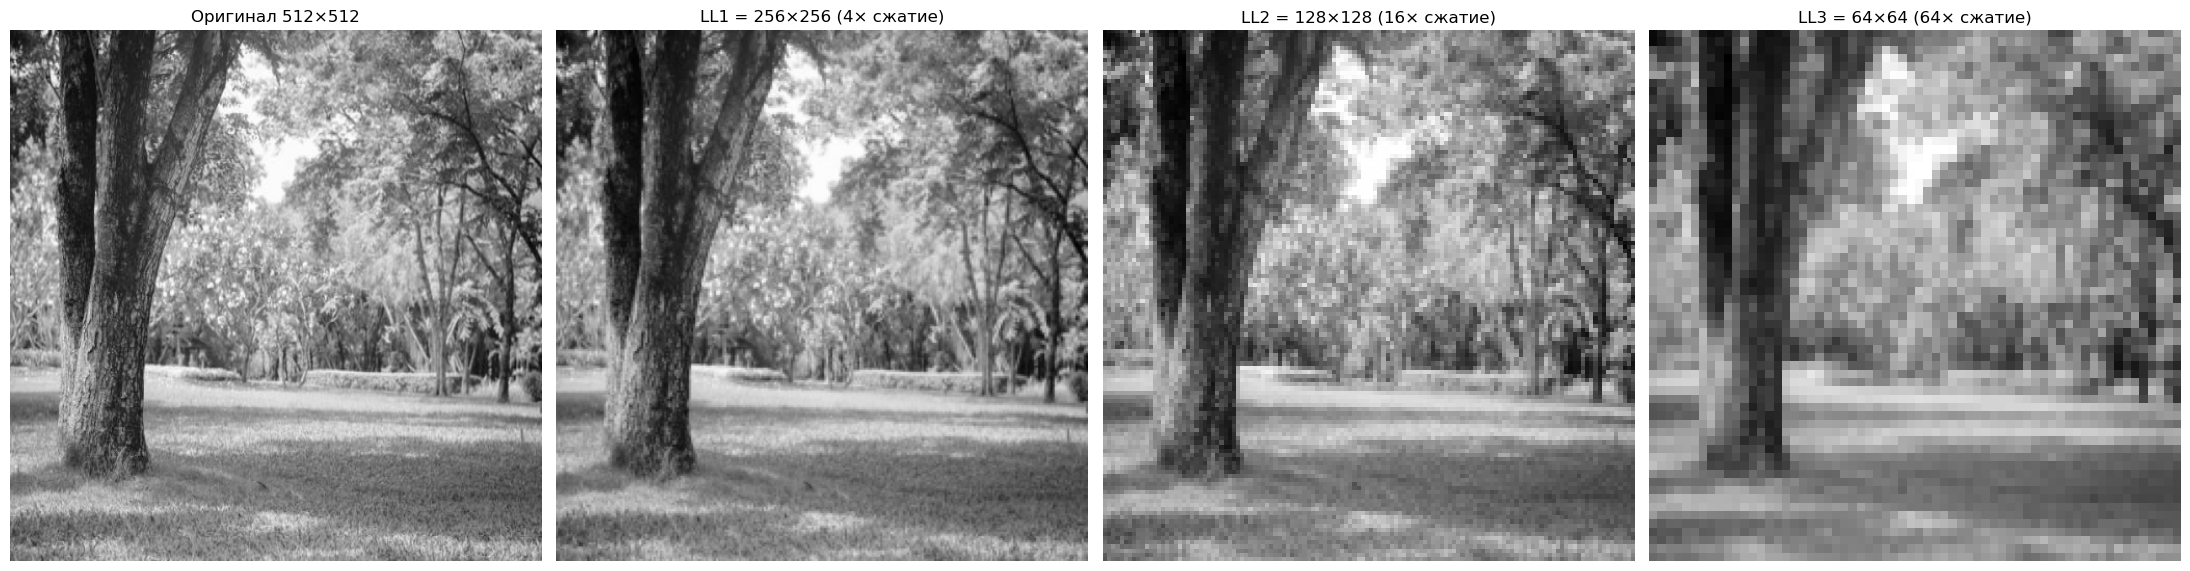

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(22, 6))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Оригинал 512×512')
axes[0].axis('off')

axes[1].imshow(ll_versions[1], cmap='gray')
axes[1].set_title('LL1 = 256×256 (4× сжатие)')
axes[1].axis('off')

axes[2].imshow(ll_versions[2], cmap='gray')
axes[2].set_title('LL2 = 128×128 (16× сжатие)')
axes[2].axis('off')

axes[3].imshow(ll_versions[3], cmap='gray')
axes[3].set_title('LL3 = 64×64 (64× сжатие)')
axes[3].axis('off')

plt.tight_layout()
plt.show()

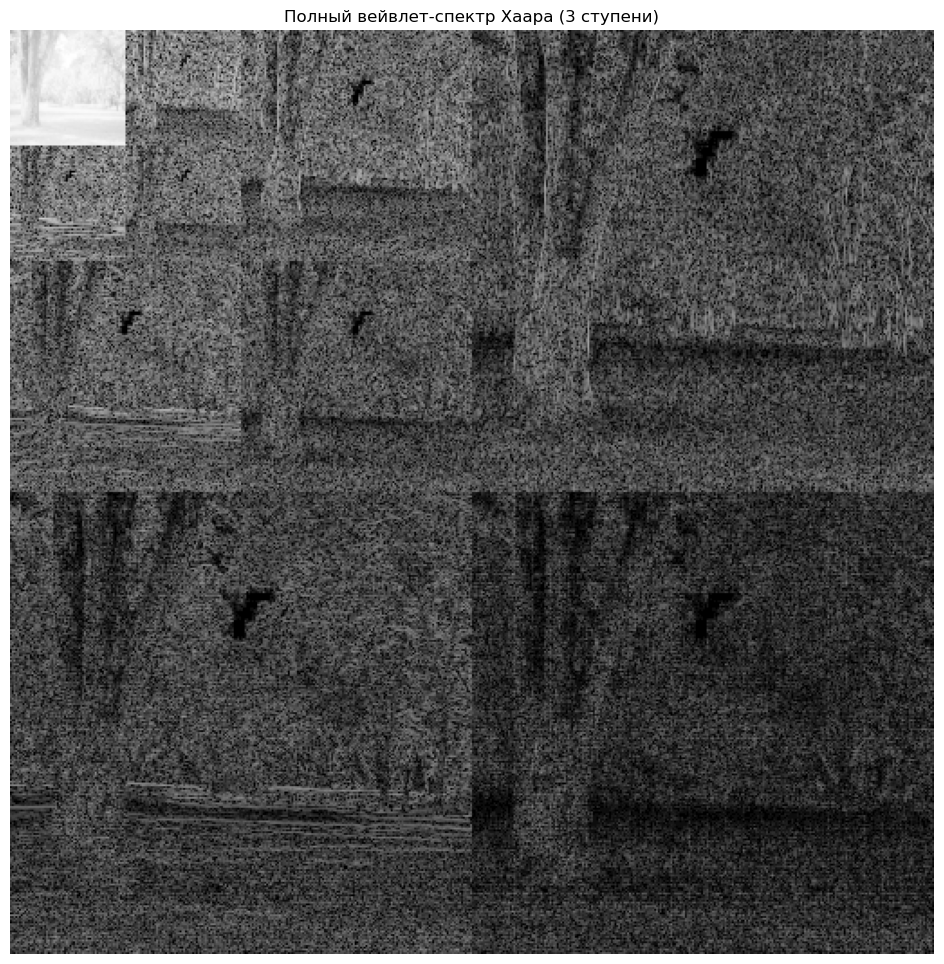

In [12]:
def build_mosaic(ll_versions, all_details):
    """Собираем всё в одну картинку 512×512."""
    cA3 = ll_versions[3]
    cH3, cV3, cD3 = all_details[2]
    cH2, cV2, cD2 = all_details[1]
    cH1, cV1, cD1 = all_details[0]

    # Уровень 3 → 128×128
    lvl3 = np.vstack([np.hstack([cA3, cH3]),
                      np.hstack([cV3, cD3])])

    # Уровень 2 → 256×256
    lvl2 = np.vstack([np.hstack([lvl3, cH2]),
                      np.hstack([cV2, cD2])])

    # Уровень 1 → 512×512
    full = np.vstack([np.hstack([lvl2, cH1]),
                      np.hstack([cV1, cD1])])
    return full

mosaic = build_mosaic(ll_versions, all_details)

# Логарифмическое масштабирование для отображения
mosaic_display = np.log(1 + np.abs(mosaic))

plt.figure(figsize=(12, 12))
plt.imshow(mosaic_display, cmap='gray')
plt.title('Полный вейвлет-спектр Хаара (3 ступени)')
plt.axis('off')
plt.show()

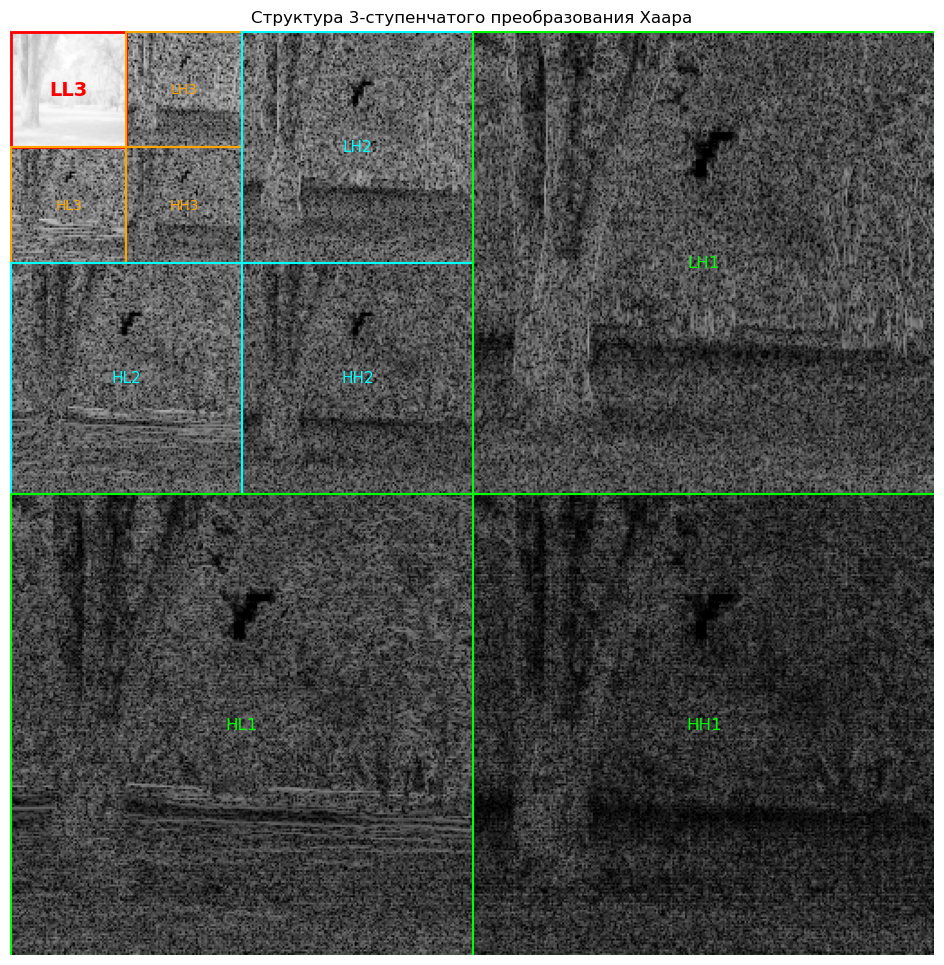

In [13]:
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(mosaic_display, cmap='gray')

# LL3 — 64×64
ax.add_patch(mpatches.Rectangle((0, 0), 64, 64, fill=False, edgecolor='red', lw=2))
ax.text(32, 32, 'LL3', color='red', ha='center', va='center',
        fontsize=14, fontweight='bold')

# Детали 3
for (x, y), label in [((64, 0), 'LH3'), ((0, 64), 'HL3'), ((64, 64), 'HH3')]:
    ax.add_patch(mpatches.Rectangle((x, y), 64, 64, fill=False, edgecolor='orange', lw=1.5))
    ax.text(x+32, y+32, label, color='orange', ha='center', va='center', fontsize=10)

# Детали 2
ax.add_patch(mpatches.Rectangle((128, 0), 128, 128, fill=False, edgecolor='cyan', lw=1.5))
ax.text(192, 64, 'LH2', color='cyan', ha='center', va='center', fontsize=11)
ax.add_patch(mpatches.Rectangle((0, 128), 128, 128, fill=False, edgecolor='cyan', lw=1.5))
ax.text(64, 192, 'HL2', color='cyan', ha='center', va='center', fontsize=11)
ax.add_patch(mpatches.Rectangle((128, 128), 128, 128, fill=False, edgecolor='cyan', lw=1.5))
ax.text(192, 192, 'HH2', color='cyan', ha='center', va='center', fontsize=11)

# Детали 1
ax.add_patch(mpatches.Rectangle((256, 0), 256, 256, fill=False, edgecolor='lime', lw=1.5))
ax.text(384, 128, 'LH1', color='lime', ha='center', va='center', fontsize=12)
ax.add_patch(mpatches.Rectangle((0, 256), 256, 256, fill=False, edgecolor='lime', lw=1.5))
ax.text(128, 384, 'HL1', color='lime', ha='center', va='center', fontsize=12)
ax.add_patch(mpatches.Rectangle((256, 256), 256, 256, fill=False, edgecolor='lime', lw=1.5))
ax.text(384, 384, 'HH1', color='lime', ha='center', va='center', fontsize=12)

plt.title('Структура 3-ступенчатого преобразования Хаара')
plt.axis('off')
plt.show()

In [14]:
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import mean_squared_error as mse_func

print("=" * 60)
print("КАЧЕСТВО СЖАТИЯ (реконструкция → 512×512)")
print("=" * 60)
print(f"{'Уровень':<15} {'Размер':>12} {'MSE':>10} {'SSIM':>10}")
print("-" * 60)

for i, name in enumerate(['LL1', 'LL2', 'LL3'], start=1):
    ll = ll_versions[i]
    upscaled = cv2.resize(ll, (512, 512), interpolation=cv2.INTER_LINEAR)
    upscaled_u8 = np.clip(upscaled, 0, 255).astype(np.uint8)

    m = mse_func(img, upscaled_u8)
    s = ssim(img, upscaled_u8, data_range=255)
    print(f"{name:<15} {ll.shape[0]:>4}×{ll.shape[1]:<4}  {m:>10.2f} {s:>10.4f}")

print("=" * 60)

КАЧЕСТВО СЖАТИЯ (реконструкция → 512×512)
Уровень               Размер        MSE       SSIM
------------------------------------------------------------
LL1              256×256      8610.54     0.4510
LL2              128×128     15271.86     0.1831
LL3               64×64      16937.99     0.1655


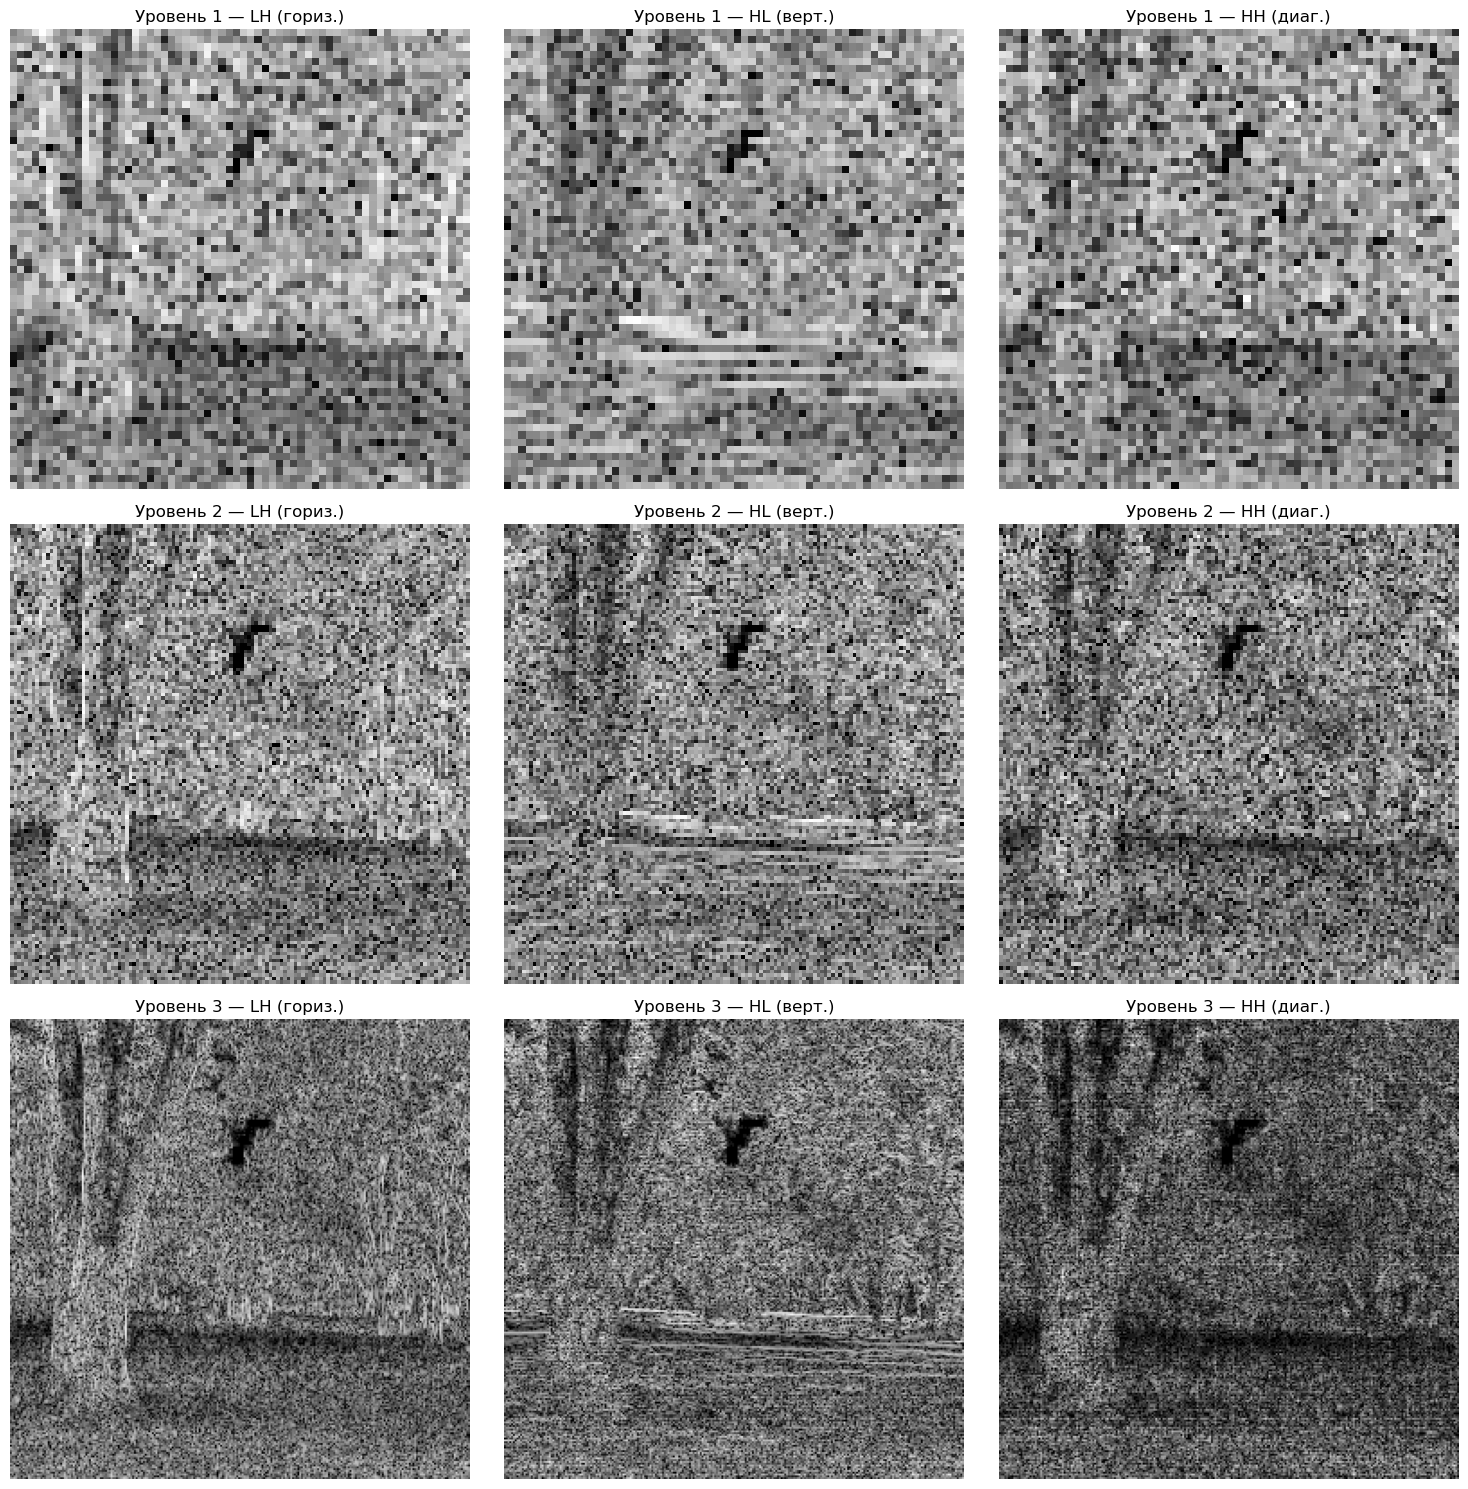

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for row, (level_idx, level_name) in enumerate([(0, 'Уровень 1'), (1, 'Уровень 2'), (2, 'Уровень 3')]):
    cH, cV, cD = all_details[level_idx]
    # Обратный порядок: сначала крупные детали (уровень 1)
    cH, cV, cD = all_details[2-level_idx]

    for col, (comp, label) in enumerate([(cH, 'LH (гориз.)'),
                                         (cV, 'HL (верт.)'),
                                         (cD, 'HH (диаг.)')]):
        axes[row][col].imshow(np.log(1 + np.abs(comp)), cmap='gray')
        axes[row][col].set_title(f'{level_name} — {label}')
        axes[row][col].axis('off')

plt.tight_layout()
plt.show()